# 결정 트리 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week07/decision_tree/lab/decision_tree.ipynb)

예 · 아니오 질문으로 나누기. 지니 불순도로 가장 좋은 질문을 직접 찾고, 실제 데이터에서 깊이를 고른다.

- **파트 1**: 지니 불순도 · 가장 좋은 질문 찾기 직접 구현 → 붓꽃 0.333, 0.11
- **파트 2**: scikit-learn 트리 그리기, 새 꽃의 경로
- **파트 3**: 타이타닉 891명: 최대 깊이를 교차 검증으로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
def download(name):
    os.makedirs("data", exist_ok=True)
    path = f"data/{name}.csv"
    if not os.path.exists(path):
        import urllib.request
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/mwaskom/seaborn-data/master/{name}.csv", path)
    return pd.read_csv(path)

iris = download("iris")
X = iris[["petal_length", "petal_width"]].to_numpy()
y = iris["species"].to_numpy()
print(iris["species"].value_counts().to_dict())

**예상 결과**

```
{'setosa': 50, 'versicolor': 50, 'virginica': 50}
```

## 파트 1. 지니 불순도와 가장 좋은 질문

$$\text{Gini} = 1 - \sum_k p_k^2, \qquad \text{after a split} = \frac{n_L}{n}\text{Gini}_L + \frac{n_R}{n}\text{Gini}_R$$

In [ ]:
def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return None  # TODO: 1 - sum of squared proportions

def split_gini(X, y, feature, threshold):
    left = X[:, feature] < threshold
    n, nl = len(y), left.sum()
    return None  # TODO: weighted average of both sides

print("root:", round(gini(y), 3))
print("petal length < 2.45:", round(split_gini(X, y, 0, 2.45), 3))
print("petal width  < 1.75:", round(split_gini(X, y, 1, 1.75), 3))

**예상 결과**

```
root: 0.667
petal length < 2.45: 0.333
petal width  < 1.75: 0.391
```

In [ ]:
def best_split(X, y):
    best = (None, None, np.inf)
    for f in range(X.shape[1]):
        values = np.unique(X[:, f])
        for t in (values[:-1] + values[1:]) / 2:           # midpoints between sorted values
            g = split_gini(X, y, f, t)
            if g < best[2]:
                best = None  # TODO: remember this feature, threshold and score
    return best

f, t, g = best_split(X, y)
print(f"best first question: feature {f} < {t:.2f}  (gini {g:.3f})")
rest = X[:, 0] >= 2.45                                    # the 100 non-setosa flowers
f2, t2, g2 = best_split(X[rest], y[rest])
print(f"best second question: feature {f2} < {t2:.2f}  (gini {g2:.3f})")

**예상 결과**

```
best first question: feature 0 < 2.45  (gini 0.333)
best second question: feature 1 < 1.75  (gini 0.110)
```

## 파트 2. scikit-learn 의 트리

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
print(export_text(tree, feature_names=["petal_length", "petal_width"]))
plt.figure(figsize=(9, 5)); plot_tree(tree, feature_names=["petal_length", "petal_width"], class_names=list(tree.classes_), filled=True); plt.show()
new_flower = np.array([[5.1, 1.8]])
print("new flower (5.1, 1.8) ->", tree.predict(new_flower)[0], "  path nodes:", tree.decision_path(new_flower).indices.tolist())

**예상 결과**

```
|--- petal_width <= 0.80
|   |--- class: setosa
|--- petal_width >  0.80
|   |--- petal_width <= 1.75
|   |   |--- class: versicolor
|   |--- petal_width >  1.75
|   |   |--- class: virginica
new flower (5.1, 1.8) -> virginica   path nodes: [0, 2, 4]
```

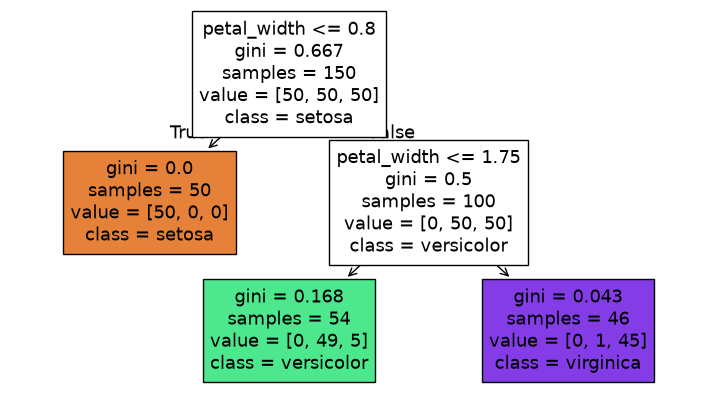

## 파트 3. 타이타닉: 누가 살아남았나

승객 891명의 등급, 성별, 나이, 요금 등으로 생존을 예측한다. 성별은 0/1 로 바꾸고, 나이가 빈 칸은 학습 데이터의 중앙값으로 채운다 (간단히 하려고 전체 중앙값을 쓰지만, 엄밀히는 지난 주의 누수 규칙대로 Pipeline 안에서 해야 한다).

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
titanic = download("titanic")
df = titanic[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]].copy()
df["sex"] = (df["sex"] == "female").astype(int)
df["age"] = df["age"].fillna(df["age"].median())
Xt, yt = df.drop(columns="survived").to_numpy(), df["survived"].to_numpy()
names = list(df.columns[1:])
cv = StratifiedKFold(5, shuffle=True, random_state=0)
depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0)
    train_acc = m.fit(Xt, yt).score(Xt, yt)
    cv_acc = None  # TODO: 5-fold CV accuracy
    print(f"max_depth={str(d):4s}: train {train_acc:.3f}   CV {cv_acc:.3f}   leaves {m.get_n_leaves()}")

**예상 결과**

```
max_depth=1   : train 0.787   CV 0.787   leaves 2
max_depth=2   : train 0.796   CV 0.770   leaves 4
max_depth=3   : train 0.827   CV 0.818   leaves 8
max_depth=4   : train 0.835   CV 0.822   leaves 15
max_depth=5   : train 0.842   CV 0.817   leaves 24
max_depth=6   : train 0.869   CV 0.807   leaves 35
max_depth=8   : train 0.891   CV 0.808   leaves 62
max_depth=10  : train 0.910   CV 0.805   leaves 90
max_depth=None: train 0.980   CV 0.788   leaves 204
```

In [ ]:
best_tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xt, yt)
print(export_text(best_tree, feature_names=names))

**예상 결과**

```
|--- sex <= 0.50
|   |--- age <= 6.50
|   |   |--- sibsp <= 2.50
|   |   |   |--- class: 1
|   |   |--- sibsp >  2.50
|   |   |   |--- class: 0
|   |--- age >  6.50
|   |   |--- pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- pclass >  1.50
|   |   |   |--- class: 0
|--- sex >  0.50
|   |--- pclass <= 2.50
|   |   |--- age <= 2.50
|   |   |   |--- class: 0
|   |   |--- age >  2.50
|   |   |   |--- class: 1
|   |--- pclass >  2.50
... (4줄 더)
```

**확인 질문**
1. 파트 1 에서 꽃잎 길이 2.45 와 꽃잎 너비 0.8 이 같은 점수다. `best_split` 은 어느 쪽을 고르나? 왜?
2. 파트 3 에서 교차 검증이 가장 높은 깊이는? 끝까지 키운 트리와 학습 · 교차 검증 정확도를 비교하자.
3. 파트 3 의 깊이 3 트리에서 첫 질문은? 타이타닉 이야기와 맞는가?
4. (도전) `min_samples_leaf` 를 1, 5, 20, 50 으로 바꿔 보자. 깊이 제한과 어떤 점이 비슷한가?

데이터 출처: Fisher (1936) Iris · Titanic passenger data (seaborn-data 사본).